# ¡Llena ese carrito!

# Introducción

Instacart es una plataforma de entregas de comestibles donde la clientela puede registrar un pedido y hacer que se lo entreguen, similar a Uber Eats y Door Dash.
El conjunto de datos es una versión modificada del original: se redujo su tamaño y se le introdujeron valores ausentes y duplicados, conservando las distribuciones de los datos originales.

El análisis se divide en tres pasos: descripción de los datos, preprocesamiento y análisis exploratorio. Cada paso incluye su plan de solución, la justificación de las decisiones tomadas y una conclusión.

## Diccionario de datos

Hay cinco tablas en el conjunto de datos y todas se usan en el preprocesamiento y en el análisis exploratorio. A continuación se muestra un diccionario de datos que enumera las columnas de cada tabla y describe los datos que contienen.

- `instacart_orders.csv`: cada fila corresponde a un pedido en la aplicación Instacart.
    - `'order_id'`: número de ID que identifica de manera única cada pedido.
    - `'user_id'`: número de ID que identifica de manera única la cuenta de cada cliente.
    - `'order_number'`: el número de veces que este cliente ha hecho un pedido.
    - `'order_dow'`: día de la semana en que se hizo el pedido (0 si es domingo).
    - `'order_hour_of_day'`: hora del día en que se hizo el pedido.
    - `'days_since_prior_order'`: número de días transcurridos desde que este cliente hizo su pedido anterior.
- `products.csv`: cada fila corresponde a un producto único que pueden comprar los clientes.
    - `'product_id'`: número ID que identifica de manera única cada producto.
    - `'product_name'`: nombre del producto.
    - `'aisle_id'`: número ID que identifica de manera única cada categoría de pasillo de víveres.
    - `'department_id'`: número ID que identifica de manera única cada departamento de víveres.
- `order_products.csv`: cada fila corresponde a un artículo pedido en un pedido.
    - `'order_id'`: número de ID que identifica de manera única cada pedido.
    - `'product_id'`: número ID que identifica de manera única cada producto.
    - `'add_to_cart_order'`: el orden secuencial en el que se añadió cada artículo en el carrito.
    - `'reordered'`: 0 si el cliente nunca ha pedido este producto antes, 1 si lo ha pedido.
- `aisles.csv`
    - `'aisle_id'`: número ID que identifica de manera única cada categoría de pasillo de víveres.
    - `'aisle'`: nombre del pasillo.
- `departments.csv`
    - `'department_id'`: número ID que identifica de manera única cada departamento de víveres.
    - `'department'`: nombre del departamento.

# Paso 1. Descripción de los datos

Se leen los cinco archivos de datos con `pd.read_csv()` y los parámetros adecuados, y se revisa la información de cada DataFrame.

## Plan de solución

* Se importará la información con `pd.read_csv()` y se le pondrá un nombre diferente a cada dataframe
* Se mostrará la información de cada uno de los df con `info()`
* Se comentará lo observado en las conclusiones

In [1]:
import warnings

import sys
import os
# Le dice python que busque liberrías ahí también
sys.path.append(os.path.join('../src'))
import funciones_personales as fp

# importar librerías
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt


In [2]:
df_insta_orders = pd.read_csv('../data/instacart_orders.csv', sep=';')
df_products = pd.read_csv('../data/products.csv', sep = ';')
df_order_products = pd.read_csv('../data/order_products.csv', sep = ';')
df_aisles= pd.read_csv('../data/aisles.csv', sep = ';')
df_departments= pd.read_csv('../data/departments.csv', sep = ';')

In [3]:
# mostrar información del DataFrame de órdenes
print(df_insta_orders.info())
print(df_insta_orders.isna().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 478967 entries, 0 to 478966
Data columns (total 6 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   order_id                478967 non-null  int64  
 1   user_id                 478967 non-null  int64  
 2   order_number            478967 non-null  int64  
 3   order_dow               478967 non-null  int64  
 4   order_hour_of_day       478967 non-null  int64  
 5   days_since_prior_order  450148 non-null  float64
dtypes: float64(1), int64(5)
memory usage: 21.9 MB
None
order_id                      0
user_id                       0
order_number                  0
order_dow                     0
order_hour_of_day             0
days_since_prior_order    28819
dtype: int64


In [4]:
# mostrar información del DataFrame de productos existentes
print(df_products .info())
print(df_products.isna().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49694 entries, 0 to 49693
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   product_id     49694 non-null  int64 
 1   product_name   48436 non-null  object
 2   aisle_id       49694 non-null  int64 
 3   department_id  49694 non-null  int64 
dtypes: int64(3), object(1)
memory usage: 1.5+ MB
None
product_id          0
product_name     1258
aisle_id            0
department_id       0
dtype: int64


In [5]:
# mostrar información del DataFrame de productos por orden
print(df_order_products.info())
print(df_order_products.isna().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4545007 entries, 0 to 4545006
Data columns (total 4 columns):
 #   Column             Dtype  
---  ------             -----  
 0   order_id           int64  
 1   product_id         int64  
 2   add_to_cart_order  float64
 3   reordered          int64  
dtypes: float64(1), int64(3)
memory usage: 138.7 MB
None
order_id               0
product_id             0
add_to_cart_order    836
reordered              0
dtype: int64


In [6]:
# mostrar información del DataFrame de islas, pasillos
print(df_aisles.info())
print(df_aisles.isna().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 134 entries, 0 to 133
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   aisle_id  134 non-null    int64 
 1   aisle     134 non-null    object
dtypes: int64(1), object(1)
memory usage: 2.2+ KB
None
aisle_id    0
aisle       0
dtype: int64


In [7]:
# mostrar información del DataFrame departamentos
print(df_departments.info())
print(df_departments.isna().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   department_id  21 non-null     int64 
 1   department     21 non-null     object
dtypes: int64(1), object(1)
memory usage: 468.0+ bytes
None
department_id    0
department       0
dtype: int64


## Conclusiones sobre descripción inicial de datos

* Se encontró que todos los separadores de los csv eran ";" por lo que se utilizó el argumento `sep= ';'`
* Se identificaron los nombres de las columnas de cada DataFrame y su tipo de valor.
    * Todas las columnas de id son valores tipo int64
* Se decubrieron varios NaN en algunos registros.
    * Para insta_orders hay 28819 valores nan en la columna days_since_prior_order
    * Para products hay 1258 valores nan en la columna product_name
    * Para order_products hay 836 valores nan en la columna add_to_cart_order
    * Para aisles no hay valores nan
    * Para departments no hay valores nan

# Paso 2. Preprocesamiento de los datos

## Plan de solución

* Se identificarán y reemplazarán los valores de cada columna; primero se  revisarán por índices usando `indices = df[df.isna().any(axis=1)].index` y `df[df['nombre_columna'].isna()]`. luego se decidirá con que valor reemplazarlos
* Se buscarán y eliminarán las columnas duplicadas.

## Valores duplicados

### `orders` data frame

In [8]:
# #REVISAMOS CUÁNTAS FILAS DUPLICADAS HAY EN CADA DF


#probamos nuestra función mostrar_nan y para df_insta_orders
fp.mostrar_nan(df_insta_orders)
fp.mostrar_dupli(df_insta_orders)




# Checamos qué porcentaje de valores tenemos en NaN respecto al total
reg_total= len(df_insta_orders) # Cantidad de filas del DF
reg_sin_nan= len(df_insta_orders.dropna()) #cantidad de filas del DF sin los valores NaN
total_nan= reg_total-reg_sin_nan # Cantidad total de filas de los valores NaN
razon= round(total_nan / reg_total, 2) #Porcentaje de representación NaN vs Total
print(f"La cantidad de valores NaN ({total_nan}) del dataframe ({reg_total}) es: {razon}%")
print('-'*50) #separador visual


# Creamoms el dataframe que contiene todos los valores NaN
df_nan= df_insta_orders[df_insta_orders['days_since_prior_order'].isna()]
    #print(df_nan.head()) #imprime las filas de la columna en donde days_since_prior_order tiene valores NaN


# Utilizamos describe()  y corr() para identificar posibles correlaciones
print(f"\nParámetros estádisticos básicos:\n{df_nan.describe()}")
print('-'*50)
print(f"\nMatriz de correlación entre datos{df_nan.corr()}")
print('-'*50)





El dataframe tiene 15 filas repetidas
--------------------------------------------------

Filas con NaN en 'order_id': 0 encontradas

Filas con NaN en 'user_id': 0 encontradas

Filas con NaN en 'order_number': 0 encontradas

Filas con NaN en 'order_dow': 0 encontradas

Filas con NaN en 'order_hour_of_day': 0 encontradas

Filas con NaN en 'days_since_prior_order': 28819 encontradas

Primeras 10 filas completas conteniendo NaN para:  ' days_since_prior_order '
     order_id  user_id  order_number  order_dow  order_hour_of_day  \
28     133707   182261             1          3                 10   
96     787445    25685             1          6                 18   
100    294410   111449             1          0                 19   
103   2869915   123958             1          4                 16   
104   2521921    42286             1          3                 18   
111   2651928   142920             1          0                 14   
118    174214   148907             1          

* Con la función `mostrar_nan()` podemos apreciar que las 15 filas repetidas coinciden por haber sucedido en miércoles a las 2 am.
    * Esto puede deberse a un error de sistema ese día y hora específicos aunque no estamos seguros si solo se trata de un miercoles o diferentes miércoles.

In [9]:
# Basándote en tus hallazgos,
# Verifica todos los pedidos que se hicieron el miércoles a las 2:00 a.m.

# Filtra las filas en las que el día es miércoles y la hora 2 am
verif_1 = df_insta_orders.query("order_hour_of_day == 2 and order_dow == 3")

# Aplicamos `mostrar_dupli()` al df original y al filtrado
fp.mostrar_dupli(df_insta_orders, None, 50)
fp.mostrar_dupli(verif_1, None, 50)

    #verif_2 = df_insta_orders.query("1000 <= index <= 3500")
    #print(len(verif_1))

## Análisis estadístico
print(f"Análisis estadístico básico:\n")
print(f"Pedidos totales LOS miércoles a las 2 am: {len(verif_1)}")
print('-'*50)
print(f"Las estadísticas básicas del dataframe:\n{verif_1.describe()}")
print('-'*50)
print(f"Índices de correlación entre los datos del dataframe:\n{verif_1.corr()}")
print('-'*50)


El dataframe tiene 15 filas completamente duplicadas
--------------------------------------------------

Filas completamente duplicadas: 30 encontradas
--------------------------------------------------

Primeras 30 filas completamente duplicadas:
        order_id  user_id  order_number  order_dow  order_hour_of_day  \
204042   2125197    14050            48          3                  2   
441599   2125197    14050            48          3                  2   
284038   2845099    31189            11          3                  2   
142258   2845099    31189            11          3                  2   
145574    794638    50898            24          3                  2   
99462     794638    50898            24          3                  2   
242618   1021560    53767             3          3                  2   
311713   1021560    53767             3          3                  2   
354993    391768    57671            19          3                  2   
371905    391768    5

¿Qué sugiere este resultado?

* Filtramos el DF para mostrar filas únicamente de ese día a esa hr y aplicamos la función `mostrar_dupli()`. Realizamos un examen estadadistico básico para ver si hay correlación entre los datos.
    * No se encontró correlación entre los datos NaN.
    * Se decidió sustituir los datos NaN por -1 simbolizando que se trata del primer pedido.
    * Además se decidió borrar las repeticiones de las 15 filas.

In [10]:
# Vuelve a verificar si hay filas duplicadas
    # Primero reemplazamos los valores NaN

# Eliminamos las filas repetidas
df_insta_orders.drop_duplicates(inplace= True)
df_insta_orders.reset_index(drop=True, inplace=True)
#Sustituye los NaN por -1
df_insta_orders.fillna({'days_since_prior_order':-1}, inplace=True)

## Revisamos datos con `mostrar_nan()` y `mostrar_dupli()`
    #mostrar_nan(df_insta_orders)

fp.mostrar_dupli(df_insta_orders)
#print(duplic.sort_values('order_id'))



El dataframe tiene 0 filas completamente duplicadas
--------------------------------------------------

Filas completamente duplicadas: 0 encontradas
--------------------------------------------------


,order_id,user_id,order_number,order_dow,order_hour_of_day,days_since_prior_order


In [11]:
# Vuelve a verificar únicamente si hay IDs duplicados

# Crea variable de una función que arroja un df con las filas donde aparecen los valores duplicados
user_id_dups = fp.mostrar_dupli(df_insta_orders, 'user_id')
print(user_id_dups.value_counts('user_id').sum())
print('-'*50)
print('-'*50)
order_id_dups= fp.mostrar_dupli(df_insta_orders, 'order_id')
print(len(order_id_dups))
print(order_id_dups.value_counts('order_id').sum())


'''
    Se encontraron duplicados en  `'user, id'` lo cual pes normal ya que un
    mismo usuario puede pedir en días diferentes. Debido a que `'order_id'`
    no tene valores repetidos, si buscamos repeticiones en combinación de `'user_id'`
    y `'order_id'` no debería haber coincidencias de ambas repitiendose en filas diferentes
    
'''
# Arroja un Series vacío ya que no encuentra ningun valor > 1 que aparezca esa combinación
cuenta_comb= df_insta_orders.value_counts(['user_id','order_id'])
repeticiones = cuenta_comb[cuenta_comb > 1]
print(repeticiones)
# como era de esperarse, todo en orden.


El dataframe tiene 0 filas completamente duplicadas
--------------------------------------------------

Filas con valores duplicados en 'user_id': 423595 encontradas
--------------------------------------------------

Primeras 10 filas completas con duplicados en: 'user_id'
    order_id  user_id  order_number  order_dow  order_hour_of_day  \
0    1515936   183418            11          6                 13   
1    1690866   163593             5          5                 12   
3    1768857    82516            56          0                 20   
5    1843871    20084             5          0                 11   
6    2511640   148233            40          3                  8   
8    2266494    34954            40          5                 15   
9     446014    15356             2          4                  8   
10   1162566    43738            33          4                 11   
11    102585   191558            18          6                 16   
12   2276302   190167            2

**Hallazgos**

* Se Sustituyeron los  valorés NaN generados todos ellos en la columna `'days_since_prior_order'`.
    *  Se utilizó `fillna()` para sustituir los nan por -1 simbolizando como si fuera un primer pedido.
* Se eliminaron las 15 filas duplicadas
    * Se utilizó `drop_duplicates()` y se reinició el índice con `reset_index(drop = True)` 
* Se verificó que la repetición de `'user_id'` no se debe a un error.
    * Se reviso que los valores de la columna `'user_id'` y `'order_id'` no se repetieran más de una vez dentro del dataframe.

### `products` data frame

In [12]:
# Verifica si hay filas totalmente duplicadas
print(df_products.info())
fp.mostrar_nan(df_products)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49694 entries, 0 to 49693
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   product_id     49694 non-null  int64 
 1   product_name   48436 non-null  object
 2   aisle_id       49694 non-null  int64 
 3   department_id  49694 non-null  int64 
dtypes: int64(3), object(1)
memory usage: 1.5+ MB
None

El dataframe tiene 0 filas repetidas
--------------------------------------------------

Filas con NaN en 'product_id': 0 encontradas

Filas con NaN en 'product_name': 1258 encontradas

Primeras 10 filas completas conteniendo NaN para:  ' product_name '
     product_id product_name  aisle_id  department_id
37           38          NaN       100             21
71           72          NaN       100             21
109         110          NaN       100             21
296         297          NaN       100             21
416         417          NaN       100             21


,product_id,product_name,aisle_id,department_id


In [13]:
# Revisa únicamente si hay ID de productos duplicados
fp.mostrar_dupli(df_products, 'product_id')


El dataframe tiene 0 filas completamente duplicadas
--------------------------------------------------

Filas con valores duplicados en 'product_id': 0 encontradas
--------------------------------------------------


,product_id,product_name,aisle_id,department_id


In [14]:
# Revisa únicamente si hay nombres duplicados de productos (convierte los nombres a letras mayúsculas para compararlos mejor)
# Crea nueva columna para no tocar datos originales
df_products['product_name_new']= df_products['product_name'].str.strip().str.upper()
    # CAMBIA NOMBRES DE COLUMNAS
    #df_products.rename(columns= {'new':'product_name_new'}, inplace=True)
print(df_products.head(15))

    product_id                                       product_name  aisle_id  \
0            1                         Chocolate Sandwich Cookies        61   
1            2                                   All-Seasons Salt       104   
2            3               Robust Golden Unsweetened Oolong Tea        94   
3            4  Smart Ones Classic Favorites Mini Rigatoni Wit...        38   
4            5                          Green Chile Anytime Sauce         5   
5            6                                       Dry Nose Oil        11   
6            7                     Pure Coconut Water With Orange        98   
7            8                  Cut Russet Potatoes Steam N' Mash       116   
8            9                  Light Strawberry Blueberry Yogurt       120   
9           10     Sparkling Orange Juice & Prickly Pear Beverage       115   
10          11                                  Peach Mango Juice        31   
11          12                         Chocolate Fud

Existen nombres de producto repetidos pero que tienen diferente id, hasta ahora no se ha tomado decisión sobre qué hacer con ellos

In [15]:
# Revisa si hay nombres duplicados de productos no faltantes
# Crea un df que contiene todas las filas  para los valores duplicados en la columna seleccionada
filtro= fp.mostrar_dupli(df_products, 'product_name_new')
# Imprime el df acomodando por nombre de la columna seleccionada
print(filtro.sort_values('product_name_new'))
#Imprime un series con el nombre único de producto y su número de repeticiones
print(filtro['product_name_new'].value_counts())
print('-'*50)
# Imprime la cantidad de valores únicos del df
print(filtro['product_name_new'].nunique())



El dataframe tiene 0 filas completamente duplicadas
--------------------------------------------------

Filas con valores duplicados en 'product_name_new': 1465 encontradas
--------------------------------------------------

Primeras 10 filas completas con duplicados en: 'product_name_new'
     product_id                                product_name  aisle_id  \
37           38                                         NaN       100   
41           42                             Biotin 1000 mcg        47   
71           72                                         NaN       100   
109         110                                         NaN       100   
185         186  Fresh Scent Dishwasher Detergent with Dawn        74   
296         297                                         NaN       100   
416         417                                         NaN       100   
436         437                                         NaN       100   
439         440                                    

**Hallazgos**
* Se encontraron 1258 valores NaN en la columna `'product_name'`
    * No se ha decidido que hacer con ellos; se sugiere sustituir por `"unknown"`.
* Se cambiaron los nombres de los productos a mayúsculas y se buscó repeticiones.
    * Se encontraron al menos 103 nombres únicos de productos, aun no se ha tomado decisión de como manejarlos.
* Se encontraron valores repetidos para nombres de productos, ya que el id es el identificador único se sugiere dejarlos como están.

### `departments` data frame

In [16]:
# Revisa si hay filas totalmente duplicadas
fp.mostrar_nan(df_departments)
fp.mostrar_dupli(df_departments)


El dataframe tiene 0 filas repetidas
--------------------------------------------------

Filas con NaN en 'department_id': 0 encontradas

Filas con NaN en 'department': 0 encontradas

El dataframe tiene 0 filas completamente duplicadas
--------------------------------------------------

Filas completamente duplicadas: 0 encontradas
--------------------------------------------------


,department_id,department


In [17]:
# Revisa únicamente si hay IDs duplicadas de departamentos
fp.mostrar_dupli(df_departments,'department_id')
print(df_departments.head())
print('-'*50)
print('-'*50)

df_departments['department_new']= df_departments['department'].str.strip().str.lower().str.replace(' ','_')
print(df_departments.head())
fp.mostrar_dupli(df_departments,'department_new')
print('-'*50)
print('-'*50)


El dataframe tiene 0 filas completamente duplicadas
--------------------------------------------------

Filas con valores duplicados en 'department_id': 0 encontradas
--------------------------------------------------
   department_id department
0              1     frozen
1              2      other
2              3     bakery
3              4    produce
4              5    alcohol
--------------------------------------------------
--------------------------------------------------
   department_id department department_new
0              1     frozen         frozen
1              2      other          other
2              3     bakery         bakery
3              4    produce        produce
4              5    alcohol        alcohol

El dataframe tiene 0 filas completamente duplicadas
--------------------------------------------------

Filas con valores duplicados en 'department_new': 0 encontradas
--------------------------------------------------
---------------------------------

**Hallazgos**
* Se buscaron filas repetidas y valores NaN.
    * No se encontraron filas repetidas ni valores NaN en `df_departments`.
* Se buscaron valores repetidos para ambas columnas.
    * No se encontraron repetidos en `department_id`.
    * Se creó una nueva columna con los datos de `departments` transformados a snake_case para buscar duplicados. No se encontraron duplicados en dicha columna.

### `aisles` data frame

In [18]:
# Revisa si hay filas totalmente duplicadas


# Muestra la info del df
print(df_aisles.info())
# Muestra los valores Nan dentro del df
fp.mostrar_nan(df_aisles)
print('-'*50)
# Muestra las primeras filas del df
print(df_aisles.head())
print('-'*50)
# Crea una nueva columna con los valores de `producct_name` convertidos a snake_case
df_aisles['aisle_new']= df_aisles['aisle'].str.strip().str.lower().str.replace(' ','_')
print(df_aisles.sort_values('aisle_new'))


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 134 entries, 0 to 133
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   aisle_id  134 non-null    int64 
 1   aisle     134 non-null    object
dtypes: int64(1), object(1)
memory usage: 2.2+ KB
None

El dataframe tiene 0 filas repetidas
--------------------------------------------------

Filas con NaN en 'aisle_id': 0 encontradas

Filas con NaN en 'aisle': 0 encontradas
--------------------------------------------------
   aisle_id                       aisle
0         1       prepared soups salads
1         2           specialty cheeses
2         3         energy granola bars
3         4               instant foods
4         5  marinades meat preparation
--------------------------------------------------
     aisle_id                          aisle                      aisle_new
100       101         air fresheners candles         air_fresheners_candles
65         66        

In [19]:
# Revisa únicamente si hay IDs duplicadas de pasillos
fp.mostrar_dupli(df_aisles, 'aisle_id')
print('-'*50)
print('-'*50)
fp.mostrar_dupli(df_aisles, 'aisle_new')


El dataframe tiene 0 filas completamente duplicadas
--------------------------------------------------

Filas con valores duplicados en 'aisle_id': 0 encontradas
--------------------------------------------------
--------------------------------------------------
--------------------------------------------------

El dataframe tiene 0 filas completamente duplicadas
--------------------------------------------------

Filas con valores duplicados en 'aisle_new': 0 encontradas
--------------------------------------------------


,aisle_id,aisle,aisle_new


**Hallazgos**
* Se buscaron valores NaN en el df usando la función `mostrar_nan()`. No se encontró ningún valor.
* Se buscaron valores repetidos para los id.
    * Se creó una nueva columna con los nombres de departamentos en snake_case.
    * Se utilizó la función `mostrar_dupli()` para la columna recién creada.
  No se encontraron repeticiones de valores en las columnas.


### `order_products` data frame

In [20]:
# Revisa si hay filas totalmente duplicadas

# Muestra la info del df
print(df_order_products.info())
# Muestra los valores Nan dentro del df
fp.mostrar_nan(df_order_products)
print('-'*50)
# Muestra las primeras filas del df
print(df_order_products.head())
print('-'*50)
# Muestra los parámetros estadísticos básicos del df
print(df_order_products.describe())
print('-'*50)

#Imprime por orden valores únicos en `'add_to_cart_order'` 
print(np.sort(df_order_products['add_to_cart_order'].unique()))

# comprueba si es seguro convertir 'add_to_cart_order' con np.array_equal
print(np.array_equal(df_order_products['add_to_cart_order'].dropna(), df_order_products['add_to_cart_order'].dropna().astype('int'), equal_nan=True))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4545007 entries, 0 to 4545006
Data columns (total 4 columns):
 #   Column             Dtype  
---  ------             -----  
 0   order_id           int64  
 1   product_id         int64  
 2   add_to_cart_order  float64
 3   reordered          int64  
dtypes: float64(1), int64(3)
memory usage: 138.7 MB
None

El dataframe tiene 0 filas repetidas
--------------------------------------------------

Filas con NaN en 'order_id': 0 encontradas

Filas con NaN en 'product_id': 0 encontradas

Filas con NaN en 'add_to_cart_order': 836 encontradas

Primeras 10 filas completas conteniendo NaN para:  ' add_to_cart_order '
       order_id  product_id  add_to_cart_order  reordered
737     2449164        5068                NaN          0
9926    1968313       43867                NaN          0
14394   2926893       11688                NaN          0
16418   1717990        4142                NaN          0
30114   1959075       42828              

In [21]:
# Vuelve a verificar si hay cualquier otro duplicado engañoso
fp.mostrar_dupli(df_order_products)


El dataframe tiene 0 filas completamente duplicadas
--------------------------------------------------

Filas completamente duplicadas: 0 encontradas
--------------------------------------------------


,order_id,product_id,add_to_cart_order,reordered


**Hallazgos**
* Se encontró que la columna `add_to_cart_order` tiene tipos de valores float desde el 1 hasta el 64 y varias filas con NaN.
    * Se planea cambiar los datos a enteros luego de verificar si el cambio afecta el df con `np.equal()`.
    * Se sustituirán los NaN por 999, un valor fuera del rango real de posiciones (1 a 64) que permite identificarlos.

## Valores ausentes

Al trabajar con valores duplicados, pudimos observar que también nos falta investigar valores ausentes:

* La columna `'product_name'` de la tabla products.
* La columna `'days_since_prior_order'` de la tabla orders.
* La columna `'add_to_cart_order'` de la tabla order_productos.

### `products` data frame

In [60]:
# Encuentra los valores ausentes en la columna 'product_name'
df_products['product_name_new']= df_products['product_name'].str.strip().str.lower().str.replace(' ','_')
## Muestra la info general del df
df_products.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49694 entries, 0 to 49693
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   product_id        49694 non-null  int64 
 1   product_name      49694 non-null  object
 2   aisle_id          49694 non-null  int64 
 3   department_id     49694 non-null  int64 
 4   product_name_new  49694 non-null  object
dtypes: int64(3), object(2)
memory usage: 1.9+ MB


In [23]:
#  ¿Todos los nombres de productos ausentes están relacionados con el pasillo con ID 100?

# Devuelve un df con todal las filas donde hay valores NaN para columna seleccionada
# Muestra la cantidad y las filas con valores Nan, asigna el df de los valores NaN
nan_df_prods= fp.mostrar_nan(df_products)
print(len(nan_df_prods))
'''
    Muestra que para todos los valores NaN existe un único valor para `'aisle_id'` (100)
'''
nan_df_prods['aisle_id'].unique()


El dataframe tiene 0 filas repetidas
--------------------------------------------------

Filas con NaN en 'product_id': 0 encontradas

Filas con NaN en 'product_name': 1258 encontradas

Primeras 10 filas completas conteniendo NaN para:  ' product_name '
     product_id product_name  aisle_id  department_id product_name_new
37           38          NaN       100             21              NaN
71           72          NaN       100             21              NaN
109         110          NaN       100             21              NaN
296         297          NaN       100             21              NaN
416         417          NaN       100             21              NaN
436         437          NaN       100             21              NaN
439         440          NaN       100             21              NaN
471         472          NaN       100             21              NaN
490         491          NaN       100             21              NaN
555         556          NaN       

array([100])

In [62]:
# ¿Todos los nombres de productos ausentes están relacionados con el departamento con ID 21?
## SI
print(len(nan_df_prods))
'''
    Muestra que para todos los valores NaN existe un único valor para `'department_id'` (21)
'''
nan_df_prods['department_id'].unique()

1258


array([21])

In [25]:
# Usa las tablas department y aisle para revisar los datos del pasillo con ID 100 y el departamento con ID 21.
# Revisar qué es el pasillo ID 100
print("Pasillo ID 100:")
print(df_aisles[df_aisles['aisle_id'] == 100])

# Revisar qué es el departamento ID 21  
print("\nDepartamento ID 21:")
print(df_departments[df_departments['department_id'] == 21])


Pasillo ID 100:
    aisle_id    aisle aisle_new
99       100  missing   missing

Departamento ID 21:
    department_id department department_new
20             21    missing        missing


In [63]:
# Completa los nombres de productos ausentes con 'Unknown'

# Sustituye valores NaN por `'Unknwon' en la columna `product_name_new`
df_products.fillna({'product_name_new': 'Unknown'}, inplace=True)


fp.mostrar_nan(df_products, 'product_name_new')


El dataframe tiene 0 filas repetidas
--------------------------------------------------

Filas con NaN en 'product_name_new': 0 encontradas


,product_id,product_name,aisle_id,department_id,product_name_new


**Hallazgos**
* Se encontraron 1258 NaN para la columna `'product_name_new'`(mismos que para `'product_name'`).
* Todos los valores Nan aparecen siempre cuando coinciden la columna `department_id = 21`  y la columna `'aisle_id = 100'` cuyos iidicadores de referencia para ambas columnas (nombres) es `'missing'`.
    * Del df original, se filtra un dataframe con los valores NaN y otro con todas las filas en las cuales los valores para las columnas `aisle_id` y `department_id` son 100 y 21 respectivamente.
        * Se utilizan, `len()` y `unique()` para demostrar que los valores NaN corresponden a los valores de columna 100 y 21.
        * Se utiliza `describe()` para mostrar que la cantidad de filas donde las columnas `'aisle_id'= 100` y`'department_id'=21` del df original  es la misma que del total de valores NaN en la columna`product_name_new`.
    * Al no encontrar valores repetidos para `product_id`. Se decide cambiar los valores NaN en la columna `'product_name_new'`al string `'Unknwon'`.


### `orders` data frame

In [64]:
# Encuentra los valores ausentes

## Muestra la información general del df
print(df_insta_orders.info())

## Muestra los valores ausentes del dataframe `'df_insta_orders'`.
nan_df_insta_orders= fp.mostrar_nan(df_insta_orders)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 478952 entries, 0 to 478951
Data columns (total 6 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   order_id                478952 non-null  int64  
 1   user_id                 478952 non-null  int64  
 2   order_number            478952 non-null  int64  
 3   order_dow               478952 non-null  int64  
 4   order_hour_of_day       478952 non-null  int64  
 5   days_since_prior_order  478952 non-null  float64
dtypes: float64(1), int64(5)
memory usage: 21.9 MB
None

El dataframe tiene 0 filas repetidas
--------------------------------------------------

Filas con NaN en 'order_id': 0 encontradas

Filas con NaN en 'user_id': 0 encontradas

Filas con NaN en 'order_number': 0 encontradas

Filas con NaN en 'order_dow': 0 encontradas

Filas con NaN en 'order_hour_of_day': 0 encontradas

Filas con NaN en 'days_since_prior_order': 0 encontradas


In [65]:
# ¿Hay algún valor ausente que no sea el primer pedido del cliente?

#cuántos valores únicos para `'odrer_number = 1'` existen en el df completo.
## Imprime cantidad de filas con valor 1 para la columna `'order_number'`.
print(len(df_insta_orders.query("order_number == 1")))
# Analizar las filas que tienen -1 (que eran NaN originalmente)
filas_primer_pedido = df_insta_orders[df_insta_orders['days_since_prior_order'] == -1]
print(f"Filas con -1 (ex-NaN): {len(filas_primer_pedido)}")
print(f"¿Todos tienen order_number = 1?: {(filas_primer_pedido['order_number'] == 1).all()}")



28817
Filas con -1 (ex-NaN): 28817
¿Todos tienen order_number = 1?: True


**Hallazgos**
* Se encontró que existen 28817 valores ausentes `-1 (antes NaN)` en la columna `'days_since_prior_order'`.
    * Se demostró que todos los valores NaN del df coinciden con `'order_number'== 1` y que todos las filas del df donde `'order_number'== 1` coinciden con `'days_since_prior_order' == -1`   

### `order_products` data frame

In [66]:
# Encuentra los valores ausentesmostrar
print(df_order_products.info())
fp.mostrar_nan(df_order_products)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4545007 entries, 0 to 4545006
Data columns (total 4 columns):
 #   Column             Dtype
---  ------             -----
 0   order_id           int64
 1   product_id         int64
 2   add_to_cart_order  int64
 3   reordered          int64
dtypes: int64(4)
memory usage: 138.7 MB
None

El dataframe tiene 0 filas repetidas
--------------------------------------------------

Filas con NaN en 'order_id': 0 encontradas

Filas con NaN en 'product_id': 0 encontradas

Filas con NaN en 'add_to_cart_order': 0 encontradas

Filas con NaN en 'reordered': 0 encontradas


,order_id,product_id,add_to_cart_order,reordered


In [30]:
# ¿Cuáles son los valores mínimos y máximos en esta columna?
df_order_products.describe(include='all')

,order_id,product_id,add_to_cart_order,reordered
count,4.545007e+06,4.545007e+06,4.544171e+06,4.545007e+06
mean,1.711166e+06,2.558084e+04,8.351669e+00,5.905025e-01
std,9.850955e+05,1.409552e+04,7.080368e+00,4.917411e-01
min,4.000000e+00,1.000000e+00,1.000000e+00,0.000000e+00
25%,8.608170e+05,1.353500e+04,3.000000e+00,0.000000e+00
50%,1.711530e+06,2.527200e+04,6.000000e+00,1.000000e+00
75%,2.561311e+06,3.793500e+04,1.100000e+01,1.000000e+00
max,3.421079e+06,4.969400e+04,6.400000e+01,1.000000e+00


In [31]:
# Guarda todas las IDs de pedidos que tengan un valor ausente en 'add_to_cart_order'
id_nan= fp.mostrar_nan(df_order_products, 'add_to_cart_order')
print(id_nan.head())
id_nan.info()


El dataframe tiene 0 filas repetidas
--------------------------------------------------

Filas con NaN en 'add_to_cart_order': 836 encontradas

Primeras 10 filas completas conteniendo NaN para:  ' add_to_cart_order '
       order_id  product_id  add_to_cart_order  reordered
737     2449164        5068                NaN          0
9926    1968313       43867                NaN          0
14394   2926893       11688                NaN          0
16418   1717990        4142                NaN          0
30114   1959075       42828                NaN          1
34183    844733       32717                NaN          0
57981     61355        5322                NaN          0
58228    936852       31373                NaN          1
62655    264710       40281                NaN          0
64336   1717990       39408                NaN          0
--------------------------------------------------
       order_id  product_id  add_to_cart_order  reordered
737     2449164        5068        

In [32]:
# ¿Todos los pedidos con valores ausentes tienen más de 64 productos?
# 1. Identificar pedidos con add_to_cart_order faltante
pedidos_con_nan = df_order_products[df_order_products['add_to_cart_order'].isna()]['order_id'].unique()
print(f"Pedidos con add_to_cart_order faltante: {len(pedidos_con_nan)}")

# 2. Contar productos por pedido (para TODOS los pedidos)
productos_por_pedido = df_order_products.groupby('order_id').size().reset_index(name='total_productos')

# 3. Filtrar solo los pedidos que tienen NaN en add_to_cart_order
pedidos_nan_info = productos_por_pedido[productos_por_pedido['order_id'].isin(pedidos_con_nan)]

# 4. Analizar estos pedidos
print(f"Estadísticas de productos en pedidos con NaN:")
print(f"Mínimo: {pedidos_nan_info['total_productos'].min()}")
print(f"Máximo: {pedidos_nan_info['total_productos'].max()}")
print(f"Promedio: {pedidos_nan_info['total_productos'].mean():.2f}")

# 5. Verificar si todos tienen más de 64 productos
pedidos_mas_64 = pedidos_nan_info[pedidos_nan_info['total_productos'] > 64]
print(f"Pedidos con NaN que tienen >64 productos: {len(pedidos_mas_64)}")
print(f"Total de pedidos con NaN: {len(pedidos_nan_info)}")

# 6. Conclusión
if len(pedidos_mas_64) == len(pedidos_nan_info):
    print("✅ TODOS los pedidos con add_to_cart_order faltante tienen más de 64 productos")
else:
    print("❌ NO todos los pedidos con add_to_cart_order faltante tienen más de 64 productos")

Pedidos con add_to_cart_order faltante: 70
Estadísticas de productos en pedidos con NaN:
Mínimo: 65
Máximo: 127
Promedio: 75.94
Pedidos con NaN que tienen >64 productos: 70
Total de pedidos con NaN: 70
✅ TODOS los pedidos con add_to_cart_order faltante tienen más de 64 productos


In [33]:
# Remplaza los valores ausentes en la columna 'add_to_cart? con 999 y convierte la columna al tipo entero.
##Remplaza NaN por 999
df_order_products.fillna({'add_to_cart_order':999}, inplace=True)

# comprueba si es seguro convertir 'add_to_cart_order' con np.array_equal y los stransforma a entero
if np.array_equal(df_order_products['add_to_cart_order'], df_order_products['add_to_cart_order'].astype('int')):
    df_order_products['add_to_cart_order']= df_order_products['add_to_cart_order'].astype('int')
df_order_products.info()
fp.mostrar_nan(df_order_products)

## Sustituimos las columnas originales por las modificadas en los df's

# Sobrescribir la columna original con la nueva
df_products['product_name'] = df_products['product_name_new']
# Eliminar la columna temporal
df_products = df_products.drop('product_name_new', axis=1)

# Sobrescribir la columna original con la nueva
df_aisles['aisle'] = df_aisles['aisle_new']
# Eliminar la columna temporal
df_aisles = df_aisles.drop('aisle_new', axis=1)

# Sobrescribir la columna original con la nueva
df_departments['department'] = df_departments['department_new']
# Eliminar la columna temporal
df_departments = df_departments.drop('department_new', axis=1)



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4545007 entries, 0 to 4545006
Data columns (total 4 columns):
 #   Column             Dtype
---  ------             -----
 0   order_id           int64
 1   product_id         int64
 2   add_to_cart_order  int64
 3   reordered          int64
dtypes: int64(4)
memory usage: 138.7 MB

El dataframe tiene 0 filas repetidas
--------------------------------------------------

Filas con NaN en 'order_id': 0 encontradas

Filas con NaN en 'product_id': 0 encontradas

Filas con NaN en 'add_to_cart_order': 0 encontradas

Filas con NaN en 'reordered': 0 encontradas


**Hallazgos**
* Se encontró que todos los valores NaN (70) de la columna `'add_to_cart_orders'` correspondían a ordenes con pedidos de entre 65 hasta 127 productos.
    * Se diecidió que en pasos siguientes se sustituirán estos valores NaN por 999.
*  Se tranformaron los valores de la columna `'add_to_cart_order'` de float64 a int64 y se sustituyeron NaN con `isna(999)`.
*  Se sustituyeron las columnas originales del df por las modificadas.

## Conclusiones – Paso 2: Preprocesamiento de los datos

Durante el preprocesamiento se analizaron y limpiaron distintos DataFrames con el objetivo de identificar valores faltantes, registros duplicados y posibles inconsistencias en los datos. A continuación, se resumen los principales hallazgos y acciones realizadas.

1. df_insta_orders
## ¿Qué se detectó?
* Se identificaron 15 filas duplicadas, todas correspondientes a pedidos realizados en miércoles a las 2:00 a.m.
* Se encontraron valores NaN en la columna days_since_prior_order.
* Se detectaron duplicados en user_id, lo cual es esperado, ya que un mismo usuario puede realizar múltiples pedidos.
* La columna add_to_cart_order contiene valores tipo float y varios NaN.
* Existen productos registrados con product_id pero sin nombre asignado, asociados al aisle_id = 100.

## ¿Cómo se analizó?
*  Se utilizó la función `mostrar_nan()` para localizar valores faltantes.
*  Se analizaron duplicados usando combinaciones de `'user_id'` y `'order_id'`, verificando que `order_id´´` no se repite.
*  Se compararon DataFrames filtrados para confirmar que los NaN coincidían con pedidos cuyo `'order_number' == 1`.
*  Se usaron funciones como  `describe()`, `unique()` y filtros condicionales para validar los hallazgos.

## ¿Cómo se solucionó?
* Los valores NaN en `'days_since_prior_order'` fueron sustituidos por -1 usando `fillna()`, interpretándolos como pedidos iniciales.
* Se eliminaron las 15 filas duplicadas con `drop_duplicates()` y se reinició el índice.
* Se confirmó que la repetición de la columna `user_id` no representa un error.
* Se planeó convertir `'add_to_cart_order'` a tipo entero y sustituir los NaN por 0 tras verificar que el cambio no afecte al DataFrame.

**Se concluyó que los productos sin nombre probablemente aún no están disponibles para venta.**

2. df_products
## ¿Qué se detectó?
* Se encontraron 1258 valores NaN en `'product_name'` y y se creó `'product_name_new'`.
* Existen nombres de productos repetidos con distinto product_id.
* Todos los valores NaN coinciden cuando aisle_id = 100 y department_id = 21.

## ¿Cómo se analizó?

* Se filtraron DataFrames con valores NaN y se compararon con los registros donde `'aisle_id'` y `'department_id'` toman los valores 100 y 21.
* Se usaron `len()`, `unique()` y `describe()` para confirmar que ambos conjuntos tienen la misma cantidad de registros.
* Se verificó que no existen `product_id` duplicados.

## ¿Cómo se solucionó?

* Se decidió sustituir los valores NaN en `product_name_new` por el string `"Unknown"`.
* Los nombres de productos se transformaron a mayúsculas para facilitar la detección de duplicados.
* Se identificaron al menos 103 nombres de productos únicos repetidos, quedando pendiente definir su tratamiento final.


3. df_order_products

## ¿Qué se detectó?
* Se encontraron 836 valores NaN en la columna `add_to_cart_order`.
* Cada valor NaN corresponde a un `product_id` distinto.

## ¿Cómo se analizó?
* Se filtró el DataFrame para analizar únicamente las filas con valores NaN.
* Se utilizó `describe()` para obtener estadísticas básicas de la columna.

## ¿Cómo se solucionó?
* Se transformó la columna `add_to_cart_order` de float64 a int64.
* Los valores NaN fueron sustituidos por 999, indicando una posición no definida en el carrito.


4. df_aisles
## Hallazgos y acciones
* No se encontraron valores NaN ni registros duplicados.
* Se creó una columna adicional en snake_case para validar duplicados mediante `mostrar_dupli() .
* El DataFrame no presentó inconsistencias.

5. df_departments
## Hallazgos y acciones
* No se encontraron filas duplicadas ni valores NaN.
* Se verificó la unicidad de `department_id`.
* Se creó una columna en snake_case para detectar duplicados en nombres de departamentos, sin resultados positivos.

# **Conclusión general**

El proceso de preprocesamiento permitió identificar y corregir valores faltantes, eliminar duplicados reales y confirmar que ciertos patrones en los datos (como pedidos iniciales o productos sin nombre) tienen una explicación lógica. Las decisiones tomadas aseguran la consistencia, integridad y calidad de los datos, permitiendo avanzar con confianza hacia las siguientes etapas del análisis.


# Paso 3. Análisis de los datos

# [A] Patrones de tiempo de los pedidos
1. Verificación de que los valores de `'order_hour_of_day'` (0 a 23) y `'order_dow'` (0 a 6) sean razonables.
2. Número de personas que hacen pedidos según la hora del día.
3. Día de la semana en que la gente hace sus compras.
4. Tiempo que la gente espera hasta su siguiente pedido, con comentarios sobre los valores mínimos y máximos.

### [A1] Verificación de que los valores sean razonables

In [34]:
# Imprime todos los valores únicos de menor a mayor de la columna 'order_hour_of_day' 
print(np.sort(df_insta_orders['order_hour_of_day'].unique()))

[ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23]


In [35]:
# Imprime todos los valores únicos de menor a mayor de la columna 'order_hour_of_day' 
print(np.sort(df_insta_orders['order_dow'].unique()))
df_insta_orders.info()

[0 1 2 3 4 5 6]
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 478952 entries, 0 to 478951
Data columns (total 6 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   order_id                478952 non-null  int64  
 1   user_id                 478952 non-null  int64  
 2   order_number            478952 non-null  int64  
 3   order_dow               478952 non-null  int64  
 4   order_hour_of_day       478952 non-null  int64  
 5   days_since_prior_order  478952 non-null  float64
dtypes: float64(1), int64(5)
memory usage: 21.9 MB


**Hallazgos A1**
* Se utizó `np.sort()` y `unique()` para acomodar los valores únicos que aparecen en cada columna.

### [A2] Para cada hora del día, ¿cuántas personas hacen órdenes?

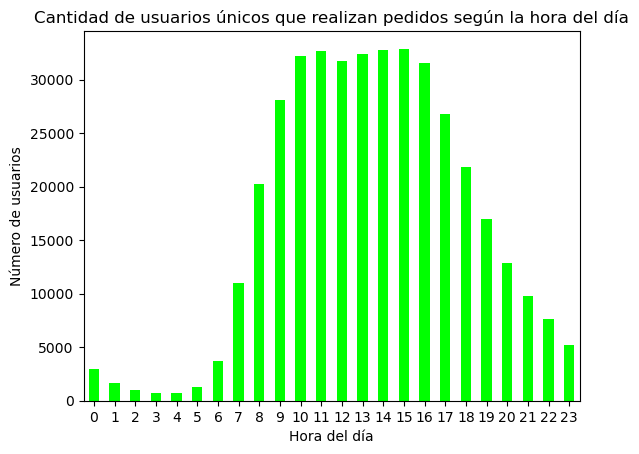

In [36]:
personas_por_dia = df_insta_orders.groupby('order_hour_of_day')['user_id'].nunique().sort_index()
personas_por_dia.plot(kind='bar',
                      xlabel= 'Hora del día',
                      ylabel= 'Número de usuarios',
                      rot=0,
                      color= 'lime',
                      title= 'Cantidad de usuarios únicos que realizan pedidos según la hora del día'
                    )
plt.show()

**Hallazgos A2**
* Parece haber dos picos muy similares (bimodal).
    * La actividad se concentra entre las 10 a.m. y las 4 p.m., con dos picos ligeros, alrededor de las 11 a.m. y las 3 p.m. (14 y 15 h), separados por una pequeña baja al mediodía.
    * Como es de esperar las horas con menos pedidos son las de la madrugada entre medianoche y 6 am.

### [A3] ¿Qué día de la semana compran víveres las personas?

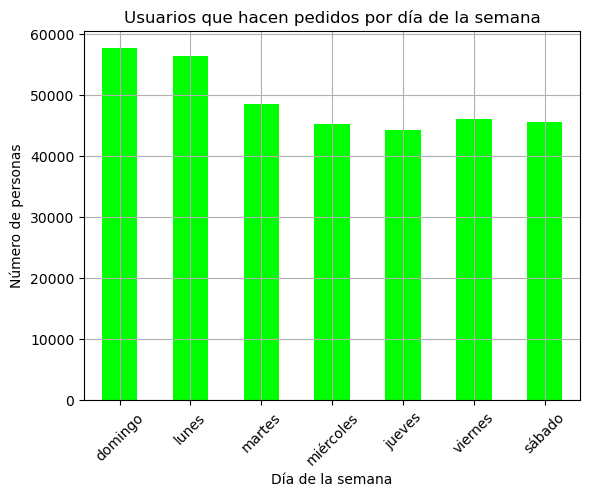

In [37]:

# Crea la lista de etiquetas del eje x
dias_semana= ['domingo','lunes', 'martes', 'miércoles', 'jueves', 'viernes', 'sábado']

# Filtra el series a graficar
persona_semana= df_insta_orders.groupby('order_dow')['user_id'].nunique().sort_index()

# Cambiar el índice por los nombres de los días
persona_semana.index = dias_semana

# Grafica el series
persona_semana.plot(xlabel= 'Día de la semana',
                    ylabel= 'Número de personas',
                    kind='bar',
                    rot =45,
                    color= 'lime',
                    title= 'Usuarios que hacen pedidos por día de la semana',
                    grid =True
                   )
plt.show()

**Hallazgos A3**
* Los días de la semana con mas personas haciendo pedidos so los domingos y lunes; el jueves es el día con menor número.
* Parece haber mucha coincidencia entre los días miércoles y sábado.

### [A4] ¿Cuánto tiempo esperan las personas hasta hacer otro pedido? Comenta sobre los valores mínimos y máximos.

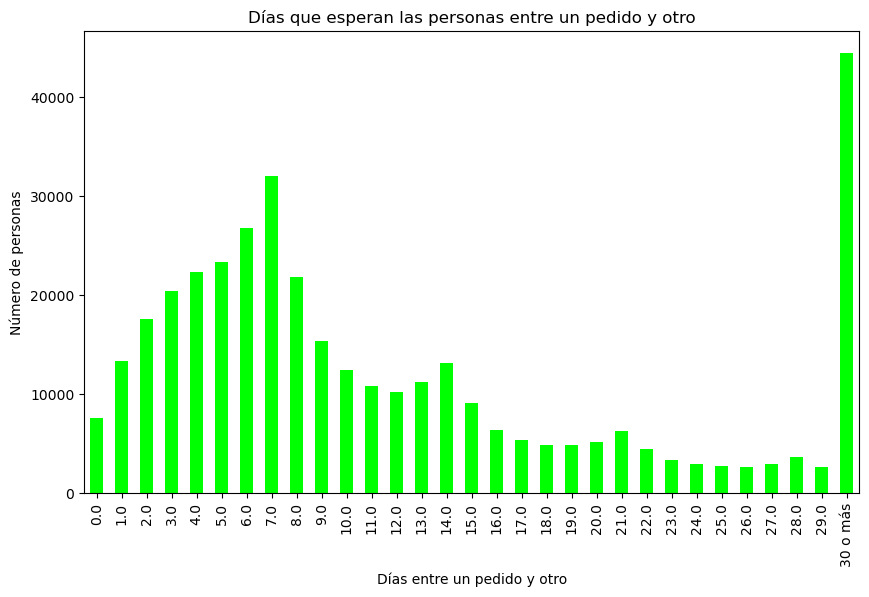

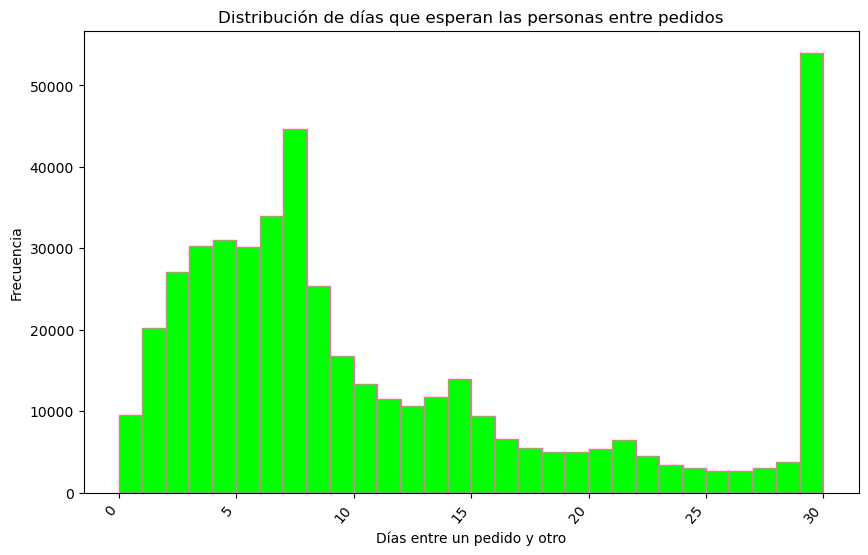

In [38]:
# OPCIÓN 1
## Gráfico de barras:
# Filtra el series a graficar
dias_espera= df_insta_orders.query("days_since_prior_order != -1").groupby('days_since_prior_order')['user_id'].nunique().sort_index()
#print(dias_espera.head(10))
# Imprime todos los valores únicos de menor a mayor de la columna 'order_hour_of_day' 
#print(np.sort(df_insta_orders['days_since_prior_order'].unique()))
# Grafica el series
ax= dias_espera.plot(xlabel= 'Días entre un pedido y otro',
                    ylabel= 'Número de personas',
                    kind='bar',
                    color= 'lime',
                    figsize= (10,6),
                    title= 'Días que esperan las personas entre un pedido y otro'
                   )
etiquetasx = ax.get_xticklabels()
etiquetasx[-1].set_text('30 o más')
ax.set_xticklabels(etiquetasx)
plt.show()

# OPCIÓN 2
## Histograma de frecuencias
## Filtra los datos originales (no agrupados)
datos_espera = df_insta_orders.query("days_since_prior_order != -1")['days_since_prior_order']

## Crea el histograma
plt.figure(figsize=(10, 6))
plt.hist(datos_espera, bins=30, color='lime', edgecolor='hotpink')
plt.xlabel('Días entre un pedido y otro')
plt.ylabel('Frecuencia')
plt.title('Distribución de días que esperan las personas entre pedidos')
plt.xticks(rotation=50, ha='right')  # ha='right' alinea el texto a la derecha
plt.show()



**Hallazgos**
* Hasta este punto no podemos saber si realmente los usuarios esperan 30 días para realizar otra compra o es el sistema el que agrupa todas las compras que sean mayores a 30 días en el día 30. Con la gráfica podemos observar que la mayoría de usuarios se concentra entre 1 y 9 días donde después los números descienden gradualmente.
* Dentro de los usuarios regulares se muestran tres picos, uno de ellos mucho mayor que los demás.
    * La mayoría de usuarios regulares realiza pedidos cada 7 días.
    * Las modas consecuentes se dan cada 14 días, cada 21 días y cada 28 días.

# [B]

1. ¿Existe alguna diferencia entre las distribuciones de `'order_hour_of_day'` de los miércoles y los sábados? Se comparan ambos días en la misma figura.
2. Distribución del número de pedidos por cliente (cuántos clientes hicieron 1 pedido, cuántos 2, cuántos 3, etc.).
3. ¿Cuáles son los 20 productos que se piden con más frecuencia (ID y nombre)?

### [B1] Diferencia entre miércoles y sábados para  `'order_hour_of_day'`.

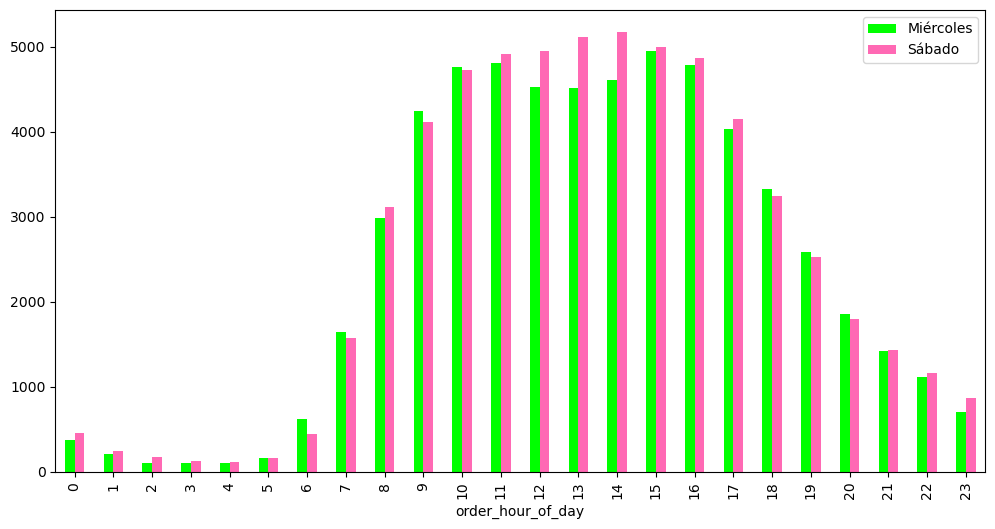

In [39]:
# OPCIÓN 1:
## Se hace el filtrado por separado, una series por cada día:
miercoles= df_insta_orders.query("order_dow == 3").groupby('order_hour_of_day')['user_id'].nunique().sort_index()
sabados= df_insta_orders.query("order_dow == 6").groupby('order_hour_of_day')['user_id'].nunique().sort_index()
## Se combinan los series en un df
df_combin= pd.DataFrame({'Miércoles': miercoles, 'Sábado': sabados})
### Graficar
df_combin.plot(kind='bar',
               figsize=(12, 6),
               color= ['lime', 'hotpink']
              )
plt.show()

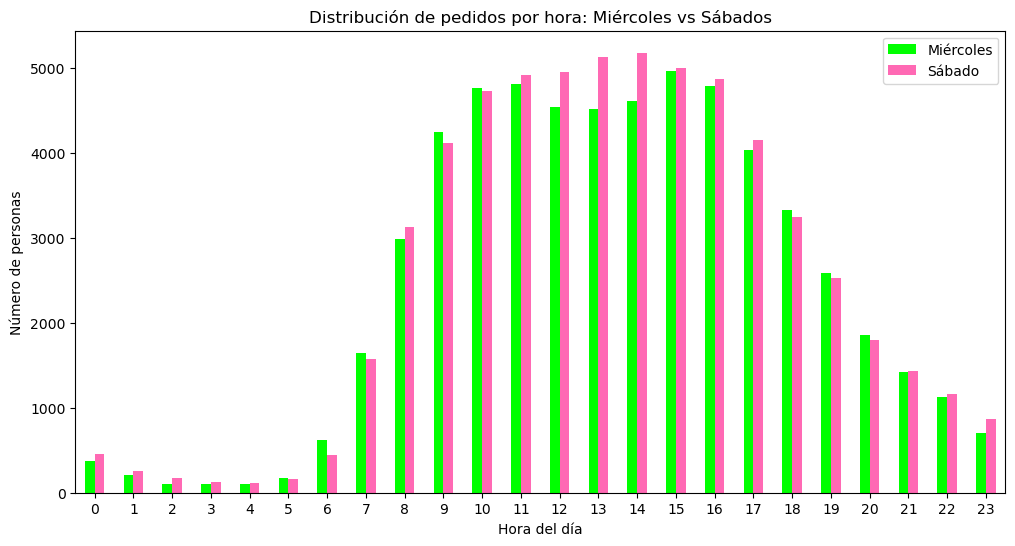

In [40]:
# OPCIÓN 2
## Se filtran ambas columnas en una sola linea: 
combin= df_insta_orders.query("order_dow == 3 or order_dow==6").groupby(['order_dow','order_hour_of_day'])['user_id'].nunique().unstack(level=0)
## Se renombran las columnas
combin.columns= ['Miércoles', 'Sábado']
### Grafaicar
# Graficar
combin.plot(kind='bar', 
            figsize=(12, 6),
            xlabel='Hora del día',
            ylabel='Número de personas',
            color=['lime', 'hotpink'],
            title='Distribución de pedidos por hora: Miércoles vs Sábados',
           )
plt.xticks(rotation=0)
plt.show()

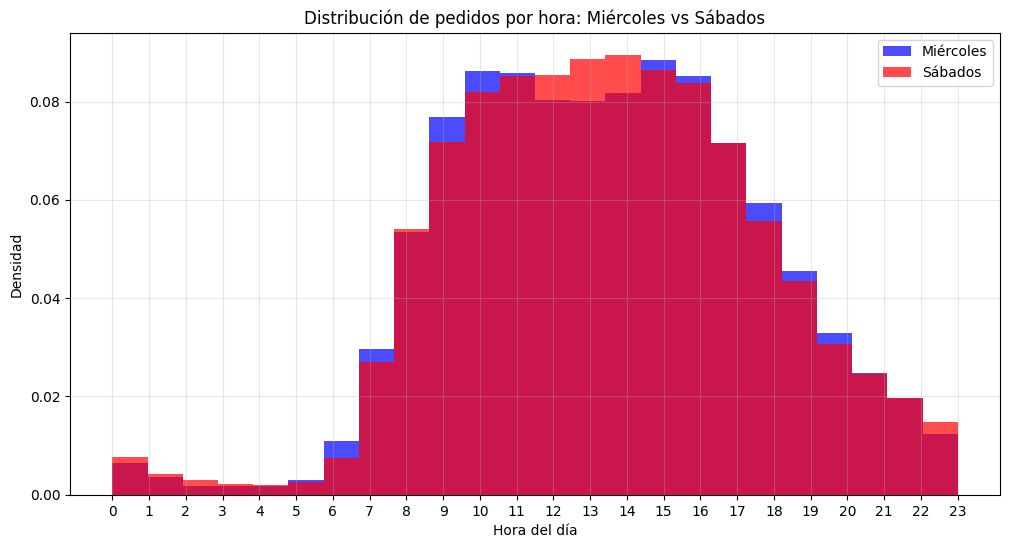

In [40]:
# OPCIÓN 3: histogramas de densidad para comparar la forma de ambas distribuciones
# Filtrar datos para miércoles (3) y sábados (6)
miercoles = df_insta_orders[df_insta_orders['order_dow'] == 3]['order_hour_of_day']
sabados = df_insta_orders[df_insta_orders['order_dow'] == 6]['order_hour_of_day']

# Crear histogramas superpuestos
plt.figure(figsize=(12, 6))
plt.hist(miercoles, bins=24, alpha=0.7, label='Miércoles', color='blue', density=True)
plt.hist(sabados, bins=24, alpha=0.7, label='Sábados', color='red', density=True)
plt.xlabel('Hora del día')
plt.ylabel('Densidad')
plt.title('Distribución de pedidos por hora: Miércoles vs Sábados')
plt.legend()
plt.xticks(range(0, 24))
plt.grid(True, alpha=0.3)
plt.show()

**Hallazgos B1**
* Las distribuciones por hora de los miércoles y los sábados son muy parecidas: en ninguna hora la diferencia en la proporción de pedidos supera 1 punto porcentual.
* El miércoles tiene una proporción algo mayor de pedidos a las 9–10 a.m. y de 6 a 8 p.m.
* El sábado tiene una proporción mayor entre las 12 y las 2 p.m. (hasta 0.8 puntos porcentuales más).

### [B2] ¿Cuál es la distribución para el número de pedidos por cliente?

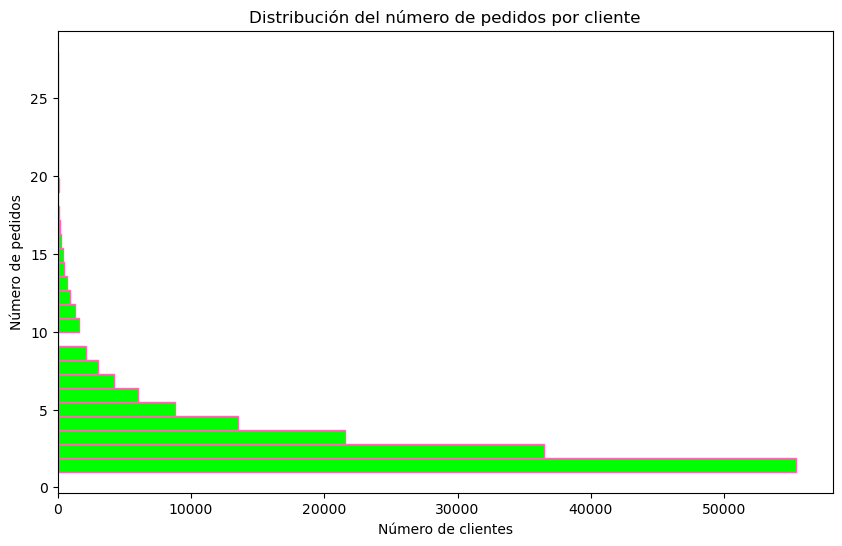

In [41]:
# OPCIÓN 1 HISTOGRAMA
## Filtra los datos del df
pedidos_por_cliente = df_insta_orders.groupby('user_id')['order_id'].count()
# Crea el histograma
plt.figure(figsize=(10, 6))
plt.hist(pedidos_por_cliente, bins=30, color='lime', edgecolor='hotpink', orientation='horizontal')
plt.xlabel('Número de clientes')
plt.ylabel('Número de pedidos')
plt.title('Distribución del número de pedidos por cliente')
plt.show()

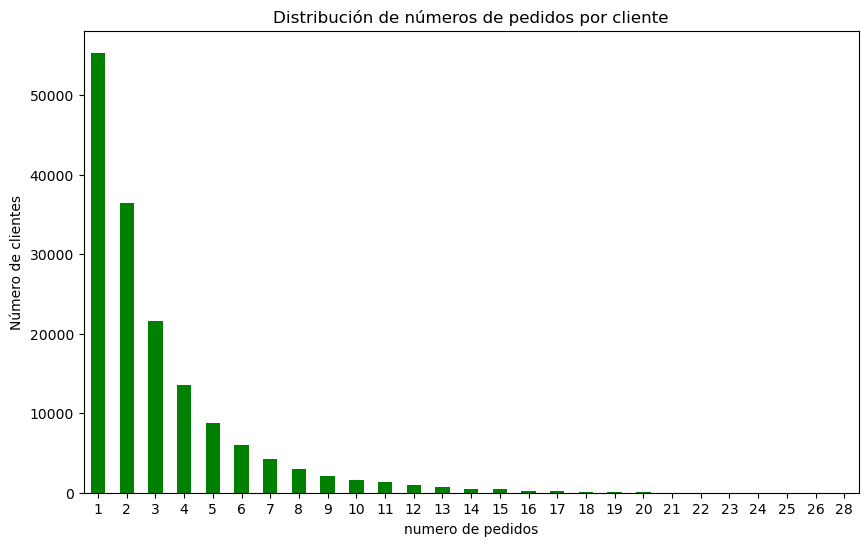

In [42]:
# OPCIÓN 2 BARRAS
## Filtrar el series
### Cuenta pedidos por cliente individual
ped_por_client= df_insta_orders.groupby('user_id')['order_id'].count()
### Cuenta cuántas veces aparece la cantidad de pedidos
distr= ped_por_client.value_counts().sort_index()
distr.plot(xlabel='numero de pedidos',
           ylabel='Número de clientes',
           color='green',
           kind='bar',
           title='Distribución de números de pedidos por cliente',
           figsize= (10,6),
           rot=0
          )
plt.show()

**Hallazgos B2**
* Como era de esperarse, mientras mayor es el número de pedidos que realiza un solo cliente menor es la cantidad de clientes que lo hacen.
    * Más de 50,000 clientes realizan un solo pedido.
    * Entre 20,000 y 37,000 clientes realizan dos o tres pedidos.
    * Cerca de 30,500 clientes (19%) realizan 5 o más pedidos; el máximo es de 28 pedidos.

### [B3] ¿Cuáles son los 20 productos más populares (ID y nombre)?

In [43]:
## Crea un series con índice como product id y columna como repeticiones, resetea el índice
prod_populares = df_order_products['product_id'].value_counts().head(20).reset_index()
## Renombra las columnas para crear un df
prod_populares.columns= ['product_id', 'repeticiones']

# Realizar el merge
result= prod_populares.merge(df_products[['product_id', 'product_name']],
                             on='product_id'                            
                            )
# Muestra el resultado de los productos más populares (id y nombre)
print(result[['product_id', 'product_name']])

    product_id              product_name
0        24852                    BANANA
1        13176    BAG OF ORGANIC BANANAS
2        21137      ORGANIC STRAWBERRIES
3        21903      ORGANIC BABY SPINACH
4        47209      ORGANIC HASS AVOCADO
5        47766           ORGANIC AVOCADO
6        47626               LARGE LEMON
7        16797              STRAWBERRIES
8        26209                     LIMES
9        27845        ORGANIC WHOLE MILK
10       27966       ORGANIC RASPBERRIES
11       22935      ORGANIC YELLOW ONION
12       24964            ORGANIC GARLIC
13       45007          ORGANIC ZUCCHINI
14       39275       ORGANIC BLUEBERRIES
15       49683            CUCUMBER KIRBY
16       28204        ORGANIC FUJI APPLE
17        5876             ORGANIC LEMON
18        8277  APPLE HONEYCRISP ORGANIC
19       40706    ORGANIC GRAPE TOMATOES


**Hallazgos B3**
* 14 de los 20 productos son orgánicos.
* 19 de los 20 son frutas o verduras; la excepción es la leche entera orgánica (ORGANIC WHOLE MILK).
    * El más vendido es el plátano por unidad, seguido por la bolsa de plátanos orgánicos.
* Los clientes compran sobre todo productos frescos, y una buena parte de ellos orgánicos.

# [C]

1. ¿Cuántos artículos suelen comprar las personas en un pedido? ¿Cómo es la distribución?
2. ¿Cuáles son los 20 principales artículos que vuelven a pedirse con mayor frecuencia (nombres e IDs)?
3. Para cada producto, ¿cuál es la tasa de repetición del pedido (número de repeticiones de pedido/total de pedidos?
4. Para cada cliente, ¿qué proporción de los productos que pidió ya los había pedido? Es la tasa de repetición de pedido por usuario en lugar de por producto.
5. ¿Cuáles son los 20 principales artículos que la gente pone primero en sus carritos (ID, nombre y número de veces en que fueron el primer artículo añadido al carrito)?

### [C1] ¿Cuántos artículos compran normalmente las personas en un pedido? ¿Cómo es la distribución?

In [44]:
#print(df_order_products.head(10))
'''
1. ¿Cuántos artículos suelen comprar las personas en un pedido? ¿Cómo es la distribución?

'''
# Cuenta la cantidadde productos pedidos para cada orden
## Opción 1
## Usa count()
grupo= df_order_products.groupby('order_id')['add_to_cart_order'].count()

## opción 2
#utiliza size() en lugar de count()
grupo_2= df_order_products.groupby('order_id').size()

# Corrobora que ambas formas de dividir son equivalentes
print((grupo == grupo_2).all())
print('-'*50)
print('-'*50)
# Descripción de estadísticos básicos
print(grupo.describe())


True
--------------------------------------------------
--------------------------------------------------
count    450046.000000
mean         10.098983
std           7.540206
min           1.000000
25%           5.000000
50%           8.000000
75%          14.000000
max         127.000000
Name: add_to_cart_order, dtype: float64


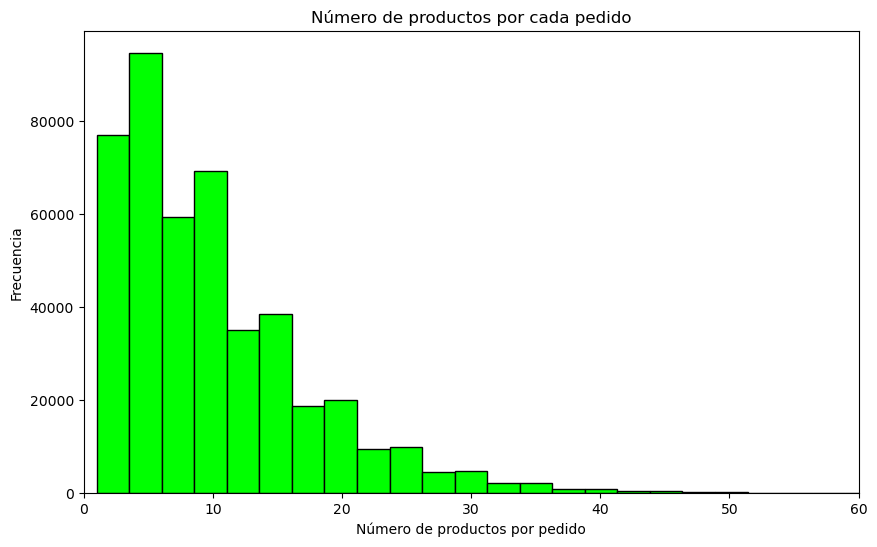

In [45]:
# Realizar un histograma de frecuencias
plt.figure(figsize=(10, 6))
plt.hist(grupo, bins=50, color='lime', edgecolor='black')
plt.xlim([0, 60])  # Establecer límites del eje x por separado
plt.xlabel('Número de productos por pedido')
plt.ylabel('Frecuencia')
plt.title('Número de productos por cada pedido')
plt.show()




**Hallazgos C1**
* El promedio es de 10 productos por pedido y la mediana de 8. El valor más frecuente es 5 productos y la mitad de los pedidos tiene entre 5 y 14 productos. La distribución tiene sesgo a la derecha, con pedidos de hasta 127 productos.

### [C2] ¿Cuáles son los 20 principales artículos que vuelven a pedirse con mayor frecuencia?

In [67]:
# Filtramos los pedidos repetidos y los contamos en función del id del producto, reseteamos índices
p_repetidos= df_order_products[df_order_products['reordered']==1]['product_id'].value_counts().head(20).reset_index()
# Renombramos columnas
p_repetidos.columns=['product_id', 'frecuencia']

# Usamos merge para obtener los nombres
mezcla= p_repetidos.merge(df_products[['product_id', 'product_name']],
                  on='product_id'                 
                 )
#muestra el resultado de los 20 productos que mas vuelven a pedirse
print(mezcla[['product_id', 'product_name']])

    product_id              product_name
0        24852                    BANANA
1        13176    BAG OF ORGANIC BANANAS
2        21137      ORGANIC STRAWBERRIES
3        21903      ORGANIC BABY SPINACH
4        47209      ORGANIC HASS AVOCADO
5        47766           ORGANIC AVOCADO
6        27845        ORGANIC WHOLE MILK
7        47626               LARGE LEMON
8        27966       ORGANIC RASPBERRIES
9        16797              STRAWBERRIES
10       26209                     LIMES
11       22935      ORGANIC YELLOW ONION
12       24964            ORGANIC GARLIC
13       45007          ORGANIC ZUCCHINI
14       49683            CUCUMBER KIRBY
15       28204        ORGANIC FUJI APPLE
16        8277  APPLE HONEYCRISP ORGANIC
17       39275       ORGANIC BLUEBERRIES
18        5876             ORGANIC LEMON
19       49235       ORGANIC HALF & HALF


In [47]:
# Muestra como lista los nombres de producto que coinciden en populares y reordenados
## Obtener los nombres que están en ambos DataFrames
coincidencias = set(result['product_name']).intersection(set(mezcla['product_name']))
print(f"Productos que aparecen en ambas listas: {len(coincidencias)}")
print(coincidencias)

Productos que aparecen en ambas listas: 19
{'ORGANIC FUJI APPLE', 'BANANA', 'ORGANIC YELLOW ONION', 'ORGANIC HASS AVOCADO', 'ORGANIC BLUEBERRIES', 'APPLE HONEYCRISP ORGANIC', 'CUCUMBER KIRBY', 'LIMES', 'LARGE LEMON', 'ORGANIC RASPBERRIES', 'ORGANIC STRAWBERRIES', 'ORGANIC GARLIC', 'ORGANIC WHOLE MILK', 'ORGANIC LEMON', 'ORGANIC AVOCADO', 'ORGANIC ZUCCHINI', 'BAG OF ORGANIC BANANAS', 'ORGANIC BABY SPINACH', 'STRAWBERRIES'}


In [59]:
# Revisamos coincidencias entre artículos populares y artículos reordenados

## Crear indicadores para ver qué productos están en cada lista
result['en_populares'] = True
mezcla['en_reordenados'] = True

## Hacer merge completo
comparacion = result.merge(mezcla[['product_name', 'en_reordenados']], 
                          on='product_name', how='outer')
comparacion['en_populares'] = comparacion['en_populares'].fillna(False)
comparacion['en_reordenados'] = comparacion['en_reordenados'].fillna(False)

## Imprime los nombres que se repiten y los que no:
print("Comparación completa:")
print(comparacion[['product_name', 'en_populares', 'en_reordenados']])

## También puedes ver solo las coincidencias:
print("\nProductos que aparecen en ambas listas:")
coincidencias = comparacion[(comparacion['en_populares'] == True) & 
                           (comparacion['en_reordenados'] == True)]
print(coincidencias[['product_name', 'en_populares', 'en_reordenados']])

## Y contar cuántas coincidencias hay:
print(f"\nTotal de productos que coinciden: {len(coincidencias)}")

Comparación completa:
                product_name  en_populares  en_reordenados
0   APPLE HONEYCRISP ORGANIC          True            True
1     BAG OF ORGANIC BANANAS          True            True
2                     BANANA          True            True
3             CUCUMBER KIRBY          True            True
4                LARGE LEMON          True            True
5                      LIMES          True            True
6            ORGANIC AVOCADO          True            True
7       ORGANIC BABY SPINACH          True            True
8        ORGANIC BLUEBERRIES          True            True
9         ORGANIC FUJI APPLE          True            True
10            ORGANIC GARLIC          True            True
11    ORGANIC GRAPE TOMATOES          True           False
12       ORGANIC HALF & HALF         False            True
13      ORGANIC HASS AVOCADO          True            True
14             ORGANIC LEMON          True            True
15       ORGANIC RASPBERRIES      

/tmp/ipykernel_8454/2802084350.py:10: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  comparacion['en_populares'] = comparacion['en_populares'].fillna(False)
/tmp/ipykernel_8454/2802084350.py:11: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  comparacion['en_reordenados'] = comparacion['en_reordenados'].fillna(False)


**Hallazgos C2**

**Metodología:**

Para identificar los productos más frecuentemente reordenados, contamos el número total de veces que cada producto aparece con `reordered == 1`. Esto nos da los **recuentos brutos de reórdenes** (cuántas veces en total se reordenó cada producto), no las **tasas de reorden** (qué proporción de las veces que se pidió un producto fue reordenado).
* Se encontró que 19 de los 20 productos más populares coinciden con los mas vueltos a pedir.
    * Organic grape tomatoes se encuentra en los más populares pero no el los más vueltos a pedir.
    * Organic half & half se encuentra en los más vueltos a pedir pero no el los mas populares

### [C3] Para cada producto, ¿cuál es la proporción de las veces que se pide y que se vuelve a pedir?

In [49]:
# muestra las veces que se pide cada producto
total_productos = df_order_products['product_id'].value_counts().reset_index()
# Renombrando columnas
total_productos.columns = ['product_id', 'total_ped']

# Verifica que no haya un denominador = 0
print(0 in total_productos['total_ped'].unique())


# Calcula las repeticiones de pedido por separado y usa map()
repeticiones = df_order_products[df_order_products['reordered']==1]['product_id'].value_counts()
total_productos['total_repet'] = total_productos['product_id'].map(repeticiones).fillna(0).astype('int')

# Añadimos la columna de la relación (división)
total_productos['relación'] = round(total_productos['total_repet'] / total_productos['total_ped'], 2)

#print(total_productos.query("relación != 0").head())

# Verificación adicional: comprobar que no hay relaciones > 1
#print("¿Hay relaciones > 1?", (total_productos['relación'] > 1).any())
print("Máxima relación:", total_productos['relación'].max())

# Se realiza el merge:
total_productos = total_productos[['product_id', 'relación']].merge(df_products[['product_id', 'product_name']], on='product_id')
#print(total_productos[['product_id', 'product_name', 'relación']])
#print(len(total_productos.query("relación == 1")))

# Mostrar solo los top 20 productos con mayor proporción de reorden
top_reorden = total_productos.nlargest(20, 'relación')
print("Top 20 productos con mayor proporción de reorden:")
print(top_reorden[['product_id', 'product_name', 'relación']])


False
Máxima relación: 1.0
Top 20 productos con mayor proporción de reorden:
       product_id                                   product_name  relación
18581       45035                           COFFEE FLAVOR YOGURT       1.0
18764       39210              SUPER PREMIUM CHOCOLATE ICE CREAM       1.0
19085       44086       NATURAL FAT FREE CHEDDAR SHREDDED CHEESE       1.0
20240       43895                           SUGAR LAND SWEET TEA       1.0
20599        1673  FREE RIDE HIBISCUS BREW CRAFT BREWED KOMBUCHA       1.0
21331       46015                   100% COLOMBIA SUPREMO MEDIUM       1.0
22013       10463                         SONIC ENERGY REFRESHED       1.0
22171       10813                    JUMBO RANCH SUNFLOWER SEEDS       1.0
22399       38041                ORANGE SPARKLING WATER BEVERAGE       1.0
22770       37943                           BLACK CHERRY SELTZER       1.0
22871       40038                        PURE BLACK CHERRY JUICE       1.0
23410        6530      

**Hallazgos C3**
* La relación pedido, repetición de pedido tiene valores de 0 a 1, con 1809 elementos que siempre se han vuelto a pedir.

### [C4] Para cada cliente, ¿qué proporción de sus productos ya los había pedido?

In [50]:

# Lo mismo que en el ejercicio anterior pero en lugar de agrupar por 'product_id', agrupa por 'user_id'
# 1. Primero hacer merge para obtener user_id
df_order_products_con_user = df_order_products.merge(
    df_insta_orders[['order_id', 'user_id']], 
    on='order_id'
)

# 2. Total de productos pedidos por cliente
total_por_cliente = df_order_products_con_user['user_id'].value_counts().reset_index()
total_por_cliente.columns = ['user_id', 'total_ped']

# 3. Total de reórdenes por cliente
repeticiones_cliente = df_order_products_con_user[df_order_products_con_user['reordered']==1]['user_id'].value_counts()
total_por_cliente['total_repet'] = total_por_cliente['user_id'].map(repeticiones_cliente).fillna(0).astype('int64')

# 4. Calcular la proporción
total_por_cliente['proporcion_reorden'] = round(total_por_cliente['total_repet'] / total_por_cliente['total_ped'], 2)
#print(total_por_cliente[['user_id', 'proporcion_reorden']])
#print(len(total_por_cliente.query("proporcion_reorden == 1")))

# NUEVA PARTE: Mostrar explícitamente el denominador para una muestra pequeña
print("Metodología:")
print("- total_ped: Total de ítems/filas por usuario")
print("- total_repet: Ítems/filas reordenados por usuario") 
print("- proporcion_reorden: Fracción de ítems reordenados (total_repet / total_ped)")
print("\nMuestra de los primeros 10 usuarios con todos los componentes:")
print(total_por_cliente[['user_id', 'total_ped', 'total_repet', 'proporcion_reorden']].head(10))

print(f"\nUsuarios con proporción de reorden = 1.0: {len(total_por_cliente.query('proporcion_reorden == 1'))}")


Metodología:
- total_ped: Total de ítems/filas por usuario
- total_repet: Ítems/filas reordenados por usuario
- proporcion_reorden: Fracción de ítems reordenados (total_repet / total_ped)

Muestra de los primeros 10 usuarios con todos los componentes:
   user_id  total_ped  total_repet  proporcion_reorden
0   103634        580          477                0.82
1    33731        540          437                0.81
2   137629        526          444                0.84
3    23371        506          428                0.85
4   164055        504          449                0.89
5    59819        481          436                0.91
6     4694        480          386                0.80
7   186704        467          410                0.88
8   166951        458          402                0.88
9   201268        457          401                0.88

Usuarios con proporción de reorden = 1.0: 8102


**Hallazgos C4**
* La proporción entre los pedidos por cliente y su repetición tiene valores de 0 a 1, con 8102 elementos que siempre se han vuelto a pedir.

### [C5] ¿Cuáles son los 20 principales artículos que las personas ponen primero en sus carritos?

In [51]:
primeros_artic = df_order_products[df_order_products['add_to_cart_order'] ==1]['product_id'].value_counts().head(20).reset_index()
primeros_artic.columns=['product_id', 'repeticiones']
#print(primeros_artic)

# Creamos el merge
el_merge= primeros_artic.merge(df_products[['product_id', 'product_name']],
                               on='product_id'                              
                              )
# Mostramos lo que pide el ejercicio
print(el_merge[['product_id', 'product_name', 'repeticiones']])


    product_id                 product_name  repeticiones
0        24852                       BANANA         15562
1        13176       BAG OF ORGANIC BANANAS         11026
2        27845           ORGANIC WHOLE MILK          4363
3        21137         ORGANIC STRAWBERRIES          3946
4        47209         ORGANIC HASS AVOCADO          3390
5        21903         ORGANIC BABY SPINACH          3336
6        47766              ORGANIC AVOCADO          3044
7        19660                 SPRING WATER          2336
8        16797                 STRAWBERRIES          2308
9        27966          ORGANIC RASPBERRIES          2024
10       44632   SPARKLING WATER GRAPEFRUIT          1914
11       49235          ORGANIC HALF & HALF          1797
12       47626                  LARGE LEMON          1737
13         196                         SODA          1733
14       38689     ORGANIC REDUCED FAT MILK          1397
15       26209                        LIMES          1370
16       12341

In [68]:
# Revisemos cuántos artículos de esta lista coinciden con los más populares
## Crear indicadores para ver qué productos están en cada lista
result['en_populares'] = True
mezcla['en_reordenados'] = True
el_merge['en_primeros_agregados'] = True

## Hacer primer merge 
compar = result.merge(mezcla[['product_name', 'en_reordenados']], 
                          on='product_name', how='outer')
compar['en_populares'] = compar['en_populares'].fillna(False)
compar['en_reordenados'] = compar['en_reordenados'].fillna(False)

## Hacer merge completo
comparacion_final = compar.merge(el_merge[['product_name', 'en_primeros_agregados']],
                                 on ='product_name',
                                 how= 'outer'
                                )
comparacion_final['en_populares']= comparacion_final['en_populares'].fillna(False)
comparacion_final['en_reordenados']= comparacion_final['en_reordenados'].fillna(False)
comparacion_final['en_primeros_agregados']= comparacion_final['en_primeros_agregados'].fillna(False)

## Imprime los nombres que se repiten y los que no:
print("Comparación completa:")
print(comparacion_final[['product_name', 'en_populares', 'en_reordenados', 'en_primeros_agregados']])

## También puedes ver solo las coincidencias:
print("\nProductos que aparecen en las tres listas:")
coincidencias = comparacion_final[(comparacion_final['en_populares'] == True) & 
                           (comparacion_final['en_reordenados'] == True) & (comparacion_final['en_primeros_agregados'] == True)]
print(coincidencias[['product_name', 'en_populares', 'en_reordenados', 'en_primeros_agregados']])

## Y contar cuántas coincidencias hay:
print(f"\nTotal de productos que coinciden: {len(coincidencias)}")

Comparación completa:
                   product_name  en_populares  en_reordenados  \
0      APPLE HONEYCRISP ORGANIC          True            True   
1        BAG OF ORGANIC BANANAS          True            True   
2                        BANANA          True            True   
3                CUCUMBER KIRBY          True            True   
4                   HALF & HALF         False           False   
5                 HASS AVOCADOS         False           False   
6                   LARGE LEMON          True            True   
7                         LIMES          True            True   
8               ORGANIC AVOCADO          True            True   
9          ORGANIC BABY SPINACH          True            True   
10          ORGANIC BLUEBERRIES          True            True   
11           ORGANIC FUJI APPLE          True            True   
12               ORGANIC GARLIC          True            True   
13       ORGANIC GRAPE TOMATOES          True           False   
14 

/tmp/ipykernel_8454/4255081157.py:10: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  compar['en_populares'] = compar['en_populares'].fillna(False)
/tmp/ipykernel_8454/4255081157.py:11: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  compar['en_reordenados'] = compar['en_reordenados'].fillna(False)
/tmp/ipykernel_8454/4255081157.py:18: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('

**Hallazgos C5**
* El plátano por unidad y por bolsa son los productos que más se añaden primero.
* Se encontraron un total de 12 productos que coinciden con ser los más populares, los más reordenados y los que se añaden primero.

### Conclusion general del proyecto:

**Conclusiones finales generales**

En este proyecto se desarrolló un análisis estructurado del conjunto de datos de Instacart siguiendo tres etapas fundamentales: descripción de los datos (Paso 1), preprocesamiento (Paso 2) y análisis exploratorio (Paso 3). Esta metodología permitió comprender de forma progresiva la información, mejorar su calidad y extraer conclusiones relevantes sobre el comportamiento de los usuarios.

En el **Paso 1**: Descripción de los datos, se identificó la estructura general del conjunto de datos y la relación entre las distintas tablas, como pedidos, productos, pasillos y departamentos. Esta etapa fue clave para entender qué representa cada variable, detectar el tamaño del conjunto de datos y reconocer desde el inicio posibles limitaciones, como la ausencia de cierta información demográfica de los usuarios. Gracias a este paso se establecieron las bases para un análisis coherente y bien dirigido.

Durante el **Paso 2**: Preprocesamiento de los datos, se evaluó la calidad de la información mediante la detección de valores faltantes, registros duplicados e inconsistencias. La limpieza y organización de los datos permitió reducir errores y asegurar que los análisis posteriores se realizaran sobre información confiable. Este paso evidenció la importancia de preparar adecuadamente los datos, ya que pequeñas anomalías pueden afectar significativamente la interpretación de los resultados.

Finalmente, en el **Paso 3**: Análisis exploratorio de los datos, se identificaron patrones claros en el comportamiento de compra de los usuarios, como la frecuencia de reordenamiento de productos, los días y horarios con mayor actividad y la recurrencia en ciertos hábitos de consumo. Estos hallazgos sugieren que los usuarios presentan rutinas de compra relativamente estables, lo que puede ser aprovechado para mejorar estrategias de recomendación, logística y planeación comercial.

A partir de estos resultados, se proponen las siguientes recomendaciones para el negocio:

1. Optimizar campañas de recomendación y recordatorios de compra utilizando la información de productos con alta tasa de reordenamiento y los horarios recurrentes de pedido, lo que permitiría aumentar la retención de usuarios y el valor promedio por pedido.
2. Mejorar la planeación operativa y logística concentrando recursos en los días y franjas horarias con mayor volumen de pedidos, reduciendo tiempos de entrega y posibles cuellos de botella, lo que impactaría positivamente en la satisfacción del cliente.

En conjunto, el proyecto demuestra que seguir un proceso ordenado que vaya desde la comprensión inicial de los datos hasta su análisis exploratorio permite obtener conclusiones sólidas y bien fundamentadas. Además, los resultados obtenidos sientan las bases para trabajos futuros, como la implementación de modelos predictivos, segmentación de usuarios o análisis de demanda, reforzando el valor del análisis de datos en plataformas de comercio digital.

**Decisiones de preprocesamiento**
Para asegurar la validez del análisis, las decisiones de preprocesamiento se basaron en el significado de los datos. Los valores faltantes de `days_since_prior_order` corresponden a primeros pedidos (`order_number == 1`), así que se sustituyeron por -1 para distinguirlos de los pedidos siguientes sin mezclarlos con un tiempo de espera real. Los 15 registros duplicados de la tabla de pedidos (todos de miércoles a las 2 a.m.) se analizaron en contexto antes de eliminarlos.

Sobre esta base de datos limpia y consistente, el análisis exploratorio permitió identificar hallazgos conductuales clave. Primero, se observó una alta recurrencia en el reordenamiento de productos, lo que indica hábitos de consumo estables y una fuerte lealtad a ciertos artículos. Segundo, los pedidos se concentran en días y horarios específicos, lo que sugiere rutinas claras de uso de la plataforma. Finalmente, se evidenció que una parte significativa de los usuarios mantiene patrones repetitivos de compra, más que comportamientos exploratorios, lo cual refuerza el valor de estrategias basadas en personalización y recordatorios.

En conjunto, la alineación entre las decisiones de limpieza y los resultados del EDA (análisis exploratorio de datos) confirma que un preprocesamiento cuidadoso no solo mejora la calidad de los datos, sino que es determinante para revelar patrones conductuales reales. Este enfoque proporciona una base sólida para análisis posteriores orientados a predicción, segmentación de usuarios y optimización de decisiones de negocio.